=== 多核 BEM 求解无限域受压圆孔问题 ===
孔径 a=1.0m, 外边界 L=80.0m, 内压 P0=1.0e+06Pa, E=1.0e+09Pa, nu=0.3
边界单元数: 外边界=40, 内圆孔=180, 总计=220
组装系统矩阵...
矩阵组装耗时: 1.619 s
求解线性方程组...
提取近场物理场与有限差分应力...
数据提取完成，耗时: 1.245 s


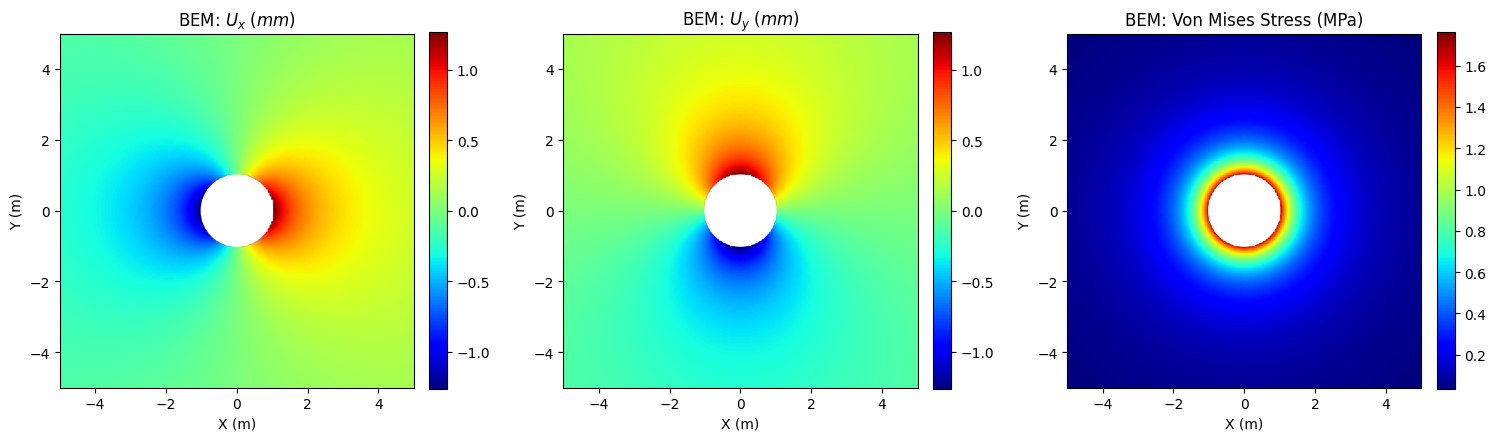

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与网格参数 (严格对齐论文截图)
# ==========================================
a = 1.0              # 圆孔半径 (m), 直径为 2a
P0 = 1.0e6           # 圆孔内压 (1 MPa)
E = 1.0e9            # 杨氏模量 (1.0 GPa)
nu = 0.3             # 泊松比

# 论文设定：外边界边长为直径的 40 倍 -> 40 * 2a = 80a
L_out = 80.0 * a     

nu_eff = nu          # 平面应变假设
G_shear = E / (2.0 * (1.0 + nu))

print(f"=== 多核 BEM 求解无限域受压圆孔问题 ===")
print(f"孔径 a={a}m, 外边界 L={L_out}m, 内压 P0={P0:.1e}Pa, E={E:.1e}Pa, nu={nu}")

def analytical_solution(x, y):
    """用于给外边界施加精确位移条件的解析解"""
    r2 = x**2 + y**2
    r = np.sqrt(r2)
    ur = (P0 * a**2) / (2 * G_shear * r)
    ux = ur * (x / r)
    uy = ur * (y / r)
    return ux, uy

# ==========================================
# 2. 生成多连通域边界网格 (外方内圆)
# ==========================================
# 论文设定：内圆孔 180 个单元，外边界 40 个单元(每边10个)
N_hole = 180  
N_side = 10   
N = N_side * 4 + N_hole

nodes = np.zeros((N, 2))
normals = np.zeros((N, 2))
lengths = np.zeros(N)
is_hole = np.zeros(N, dtype=bool)

idx = 0
# 2.1 外边界 (逆时针 CCW，保证计算域在左侧，法向朝外)
coords = np.linspace(-L_out/2, L_out/2, N_side + 1)
for i in range(N_side): # 底边
    nodes[idx] = [(coords[i]+coords[i+1])/2, -L_out/2]; normals[idx] = [0, -1]; lengths[idx] = coords[i+1]-coords[i]; idx += 1
for i in range(N_side): # 右边
    nodes[idx] = [L_out/2, (coords[i]+coords[i+1])/2]; normals[idx] = [1, 0]; lengths[idx] = coords[i+1]-coords[i]; idx += 1
for i in range(N_side): # 顶边 (反向)
    nodes[idx] = [(coords[N_side-i]+coords[N_side-i-1])/2, L_out/2]; normals[idx] = [0, 1]; lengths[idx] = coords[N_side-i]-coords[N_side-i-1]; idx += 1
for i in range(N_side): # 左边 (反向)
    nodes[idx] = [-L_out/2, (coords[N_side-i]+coords[N_side-i-1])/2]; normals[idx] = [-1, 0]; lengths[idx] = coords[N_side-i]-coords[N_side-i-1]; idx += 1

# 2.2 内圆孔 (顺时针 CW，计算域在左侧，法向指向圆心)
theta = np.linspace(0, 2*np.pi, N_hole + 1)
for i in range(N_hole):
    th1 = theta[N_hole - i]      
    th2 = theta[N_hole - i - 1]
    x1, y1 = a * np.cos(th1), a * np.sin(th1)
    x2, y2 = a * np.cos(th2), a * np.sin(th2)
    th_mid = (th1 + th2) / 2
    
    nodes[idx] = [(x1+x2)/2, (y1+y2)/2]
    normals[idx] = [-np.cos(th_mid), -np.sin(th_mid)] # 法向指向圆心
    lengths[idx] = np.sqrt((x2-x1)**2 + (y2-y1)**2)
    is_hole[idx] = True
    idx += 1

# Numba 常数项
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

print(f"边界单元数: 外边界={N_side*4}, 内圆孔={N_hole}, 总计={N}")

# ==========================================
# 3. Numba 核心积分引擎
# ==========================================
@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H = np.zeros((2*N, 2*N))
    G = np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    
    for i in prange(N):
        x_source = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]
            tx, ty = -ny, nx
            r0, r1 = 2*i, 2*i+1
            c0, c1 = 2*j, 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                G[r0, c0] = tx*(g00*tx) + nx*(g11*nx); G[r0, c1] = tx*(g00*ty) + nx*(g11*ny)
                G[r1, c0] = ty*(g00*tx) + ny*(g11*nx); G[r1, c1] = ty*(g00*ty) + ny*(g11*ny)
            else:
                y_center = nodes[j]
                H00 = H01 = H10 = H11 = 0.0
                G00 = G01 = G10 = G11 = 0.0
                for g in range(n_gauss):
                    y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                    y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                    rx = y_gpx - x_source[0]; ry = y_gpy - x_source[1]
                    r = np.sqrt(rx*rx + ry*ry)
                    rdx = rx/r; rdy = ry/r
                    dr_dn = rdx*nx + rdy*ny
                    log_1_r = np.log(1.0/r)
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                    
                H[r0, c0] = H00; H[r0, c1] = H01; H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01; G[r1, c0] = G10; G[r1, c1] = G11
    return H, G

t0 = time.time()
print("组装系统矩阵...")
H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)
print(f"矩阵组装耗时: {time.time()-t0:.3f} s")

# ==========================================
# 4. 施加边界条件并求解
# ==========================================
A = np.zeros((2*N, 2*N))
B = np.zeros(2*N)
u_known = np.zeros(2*N, dtype=bool); u_val = np.zeros(2*N)
t_known = np.zeros(2*N, dtype=bool); t_val = np.zeros(2*N)

for i in range(N):
    dof_x, dof_y = 2*i, 2*i+1
    if is_hole[i]:
        # 圆孔边界受均匀内压 P0，法向指向圆心
        t_known[dof_x] = True; t_val[dof_x] = -P0 * normals[i, 0]
        t_known[dof_y] = True; t_val[dof_y] = -P0 * normals[i, 1]
    else:
        # 外边界施加位移解析解以模拟无限大平面
        ux_ana, uy_ana = analytical_solution(nodes[i,0], nodes[i,1])
        u_known[dof_x] = True; u_val[dof_x] = ux_ana
        u_known[dof_y] = True; u_val[dof_y] = uy_ana

for k in range(2*N):
    if u_known[k]:
        A[:, k] = -G[:, k]; B -= H[:, k] * u_val[k]
    else:
        A[:, k] = H[:, k]; B += G[:, k] * t_val[k]

print("求解线性方程组...")
X = np.linalg.solve(A, B)

u_bnd = np.where(u_known, u_val, X)
t_bnd = np.where(u_known, X, t_val)

# ==========================================
# 5. 提取观测区域内场数据 (-5 到 5)
# ==========================================
@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts, N = pts.shape[0], nodes.shape[0]
    n_gauss = len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    
    for q in prange(N_pts):
        xi_x, xi_y = pts[q, 0], pts[q, 1]
        u_x = u_y = 0.0
        for j in range(N):
            y_center = nodes[j]; L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]; tx, ty = -ny, nx
            U00=U01=U10=U11=T00=T01=T10=T11=0.0
            
            for g in range(n_gauss):
                y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                rx = y_gpx - xi_x; ry = y_gpy - xi_y
                r = np.sqrt(rx*rx + ry*ry)
                rdx = rx/r; rdy = ry/r
                dr_dn = rdx*nx + rdy*ny; log_1_r = np.log(1.0/r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw; U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                
            uj_x, uj_y = u_bnd[2*j], u_bnd[2*j+1]
            tj_x, tj_y = t_bnd[2*j], t_bnd[2*j+1]
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
            
        u_out[q, 0] = u_x
        u_out[q, 1] = u_y
    return u_out

print("提取近场物理场与有限差分应力...")
# 观测区域：修改为 [-5, 5]
L_plot = 5.0 * a
grid_size = 200 # 为保证图片分辨率平滑，网格稍微加密到200x200
coords_1d = np.linspace(-L_plot, L_plot, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
internal_pts_raw = np.c_[XX.ravel(), YY.ravel()]

# 核心逻辑：只计算圆孔外部的点，内部填 NaN
r_pts = np.sqrt(internal_pts_raw[:,0]**2 + internal_pts_raw[:,1]**2)
valid_mask = (r_pts > a * 1.02) # 为了避免边界奇异性，往外退一点点
internal_pts = internal_pts_raw[valid_mask]

t2 = time.time()
u_int = calc_internal_u_numba(internal_pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

# 中心差分求应变与应力
eps = 1e-4
u_px = calc_internal_u_numba(internal_pts + np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_mx = calc_internal_u_numba(internal_pts - np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

du_dx = (u_px - u_mx) / (2*eps); du_dy = (u_py - u_my) / (2*eps)
eps_xx = du_dx[:, 0]; eps_yy = du_dy[:, 1]; eps_xy = 0.5 * (du_dx[:, 1] + du_dy[:, 0])

lam = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_lame = E / (2 * (1 + nu))

sig_xx = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_xx
sig_yy = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_yy
sig_xy = 2 * mu_lame * eps_xy
sig_zz = nu * (sig_xx + sig_yy)

von_mises = np.sqrt(0.5 * ((sig_xx - sig_yy)**2 + (sig_yy - sig_zz)**2 + (sig_zz - sig_xx)**2) + 3 * sig_xy**2)

# 将有效数据映射回全网格
U_X_map = np.full(grid_size*grid_size, np.nan)
U_X_map[valid_mask] = u_int[:, 0]

U_Y_map = np.full(grid_size*grid_size, np.nan)
U_Y_map[valid_mask] = u_int[:, 1]

VM_map = np.full(grid_size*grid_size, np.nan)
VM_map[valid_mask] = von_mises

print(f"数据提取完成，耗时: {time.time()-t2:.3f} s")

# ==========================================
# 6. 绘图出图 (Ux, Uy 单位改为 mm, Von Mises 为 MPa)
# ==========================================
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(18, 5))
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)
extent = [-L_plot, L_plot, -L_plot, L_plot]

# 子图 1: Ux 方向位移 (单位: mm)
ax0 = fig.add_subplot(gs[0, 0])
# 1e3 将 m 转换为 mm
im0 = ax0.imshow(U_X_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet')
ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
ax0.set_title('BEM: $U_x$ ($mm$)')
ax0.add_patch(plt.Circle((0, 0), a, color='white', fill=True)) # 遮盖孔洞

# 子图 2: Uy 方向位移 (单位: mm)
ax1 = fig.add_subplot(gs[0, 1])
# 1e3 将 m 转换为 mm
im1 = ax1.imshow(U_Y_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet')
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title('BEM: $U_y$ ($mm$)')
ax1.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

# 子图 3: Von Mises 应力 (单位: MPa)
ax2 = fig.add_subplot(gs[0, 2])
# 1e-6 将 Pa 转换为 MPa
im2 = ax2.imshow(VM_map.reshape(grid_size, grid_size)/1e6, origin='lower', extent=extent, cmap='jet')
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title('BEM: Von Mises Stress (MPa)')
ax2.add_patch(plt.Circle((0, 0), a, color='white', fill=True))

plt.show()


## Export BEM full-field data for the 3 x 3 comparison figure

Run this cell after the BEM solution and field-recovery code above. The exported file uses SI units consistently: displacement in m and stress in Pa. It can be loaded directly by the separate comparison-figure notebook.


In [2]:
# ============================================================
# 7. Export BEM fields for the unified 3 x 3 comparison figure
# ============================================================
from pathlib import Path
import numpy as np

required_variables = [
    "XX", "YY", "grid_size", "valid_mask", "a", "L_plot",
    "U_X_map", "U_Y_map", "VM_map",
    "sig_xx", "sig_yy", "sig_xy", "von_mises",
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise NameError(
        "Please run the BEM solution cell first. Missing variables: "
        + ", ".join(missing_variables)
    )

grid_shape = (int(grid_size), int(grid_size))
expected_size = int(grid_size) * int(grid_size)
valid_mask_export = np.asarray(valid_mask, dtype=bool).reshape(-1)

if valid_mask_export.size != expected_size:
    raise ValueError(
        f"valid_mask has {valid_mask_export.size} entries, "
        f"but the grid requires {expected_size}."
    )


def _reshape_full_map(values, name):
    values = np.asarray(values, dtype=float).reshape(-1)
    if values.size != expected_size:
        raise ValueError(
            f"{name} has {values.size} entries, but the grid requires {expected_size}."
        )
    return values.reshape(grid_shape)


def _map_valid_values(values, name):
    values = np.asarray(values, dtype=float).reshape(-1)
    n_valid = int(np.count_nonzero(valid_mask_export))
    if values.size != n_valid:
        raise ValueError(
            f"{name} has {values.size} entries, "
            f"but valid_mask contains {n_valid} exterior points."
        )
    full = np.full(expected_size, np.nan, dtype=float)
    full[valid_mask_export] = values
    return full.reshape(grid_shape)


# Existing displacement and von Mises maps are already full flattened grids.
ux_map_si = _reshape_full_map(U_X_map, "U_X_map")
uy_map_si = _reshape_full_map(U_Y_map, "U_Y_map")
vm_map_si = _reshape_full_map(VM_map, "VM_map")

# Preserve the individual stress components for radial-line and error plots.
sxx_map_si = _map_valid_values(sig_xx, "sig_xx")
syy_map_si = _map_valid_values(sig_yy, "sig_yy")
sxy_map_si = _map_valid_values(sig_xy, "sig_xy")

X_export = np.asarray(XX, dtype=float)
Y_export = np.asarray(YY, dtype=float)
if X_export.shape != grid_shape or Y_export.shape != grid_shape:
    raise ValueError(
        f"XX/YY shapes must be {grid_shape}; got {X_export.shape} and {Y_export.shape}."
    )

result_dir = Path.cwd() / "field_results"
result_dir.mkdir(parents=True, exist_ok=True)
output_file = result_dir / "bem_fields.npz"

np.savez_compressed(
    output_file,
    X=X_export,
    Y=Y_export,
    valid_mask=valid_mask_export.reshape(grid_shape),
    ux=ux_map_si,       # m
    uy=uy_map_si,       # m
    sxx=sxx_map_si,     # Pa
    syy=syy_map_si,     # Pa
    sxy=sxy_map_si,     # Pa
    vm=vm_map_si,       # Pa
    a=float(a),
    L_plot=float(L_plot),
    grid_size=int(grid_size),
    displacement_unit="m",
    stress_unit="Pa",
    method="BEM",
)

# Immediate read-back validation prevents a damaged or inconsistent file from
# being passed to the final plotting notebook.
with np.load(output_file) as check:
    for key in ["X", "Y", "ux", "uy", "sxx", "syy", "sxy", "vm"]:
        if check[key].shape != grid_shape:
            raise RuntimeError(
                f"Export validation failed: {key} has shape {check[key].shape}."
            )
    if check["displacement_unit"].item() != "m":
        raise RuntimeError("Unexpected displacement unit in exported file.")
    if check["stress_unit"].item() != "Pa":
        raise RuntimeError("Unexpected stress unit in exported file.")

print(f"BEM field data saved successfully:\n{output_file.resolve()}")
print(f"Grid: {grid_size} x {grid_size}; exterior points: {valid_mask_export.sum()}")
print(
    "Finite ranges (SI units):\n"
    f"  ux: [{np.nanmin(ux_map_si):.6e}, {np.nanmax(ux_map_si):.6e}] m\n"
    f"  uy: [{np.nanmin(uy_map_si):.6e}, {np.nanmax(uy_map_si):.6e}] m\n"
    f"  vm: [{np.nanmin(vm_map_si):.6e}, {np.nanmax(vm_map_si):.6e}] Pa"
)


BEM field data saved successfully:
C:\Users\magic\Desktop\KM-PIKFNN\圆孔受压\field_results\bem_fields.npz
Grid: 200 x 200; exterior points: 38712
Finite ranges (SI units):
  ux: [-1.264740e-03, 1.264740e-03] m
  uy: [-1.264740e-03, 1.264740e-03] m
  vm: [3.473691e+04, 1.761171e+06] Pa
